In [1]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Data Understanding

In [2]:
# Load Dataset
df = pd.read_csv('../data/ecommerce_customer_behavior_dataset_v2.csv')

# Preview Dataset
df.sample(5).T

,2277,8215,4588,10089,922
Order_ID,ORD_000689-2,ORD_002395-6,ORD_001321-2,ORD_002964-1,ORD_000280-1
Customer_ID,CUST_00689,CUST_02395,CUST_01321,CUST_02964,CUST_00280
Date,2023-12-31,2024-02-07,2023-11-09,2023-08-27,2023-04-30
Age,43,33,35,22,30
Gender,Female,Male,Female,Male,Female
City,Izmir,Ankara,Adana,Adana,Gaziantep
Product_Category,Beauty,Sports,Sports,Fashion,Fashion
Unit_Price,116.39,127.37,253.54,318.34,363.61
Quantity,2,2,4,3,1
Discount_Amount,0.0,0.0,75.99,0.0,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17049 entries, 0 to 17048
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  17049 non-null  str    
 1   Customer_ID               17049 non-null  str    
 2   Date                      17049 non-null  str    
 3   Age                       17049 non-null  int64  
 4   Gender                    17049 non-null  str    
 5   City                      17049 non-null  str    
 6   Product_Category          17049 non-null  str    
 7   Unit_Price                17049 non-null  float64
 8   Quantity                  17049 non-null  int64  
 9   Discount_Amount           17049 non-null  float64
 10  Total_Amount              17049 non-null  float64
 11  Payment_Method            17049 non-null  str    
 12  Device_Type               17049 non-null  str    
 13  Session_Duration_Minutes  17049 non-null  int64  
 14  Pages_Viewed     

In [4]:
# Identifikasi Unique Value Pada Kolom Kategorikal Pada Dataset
categorical_columns = ['Order_ID', 'Customer_ID', 'Gender', 'City', 'Product_Category',
                        'Payment_Method', 'Device_Type', 'Is_Returning_Customer', 'Customer_Rating']

for col in categorical_columns:
  print(f"{col}: {df[col].nunique()} unique values")
  print(df[col].value_counts())
  print("\n")

Order_ID: 17049 unique values
Order_ID
ORD_000001-1    1
ORD_000001-2    1
ORD_000001-3    1
ORD_000002-1    1
ORD_000002-2    1
               ..
ORD_004999-1    1
ORD_005000-1    1
ORD_005000-2    1
ORD_005000-3    1
ORD_005000-4    1
Name: count, Length: 17049, dtype: int64


Customer_ID: 5000 unique values
Customer_ID
CUST_00016    10
CUST_00092    10
CUST_00154    10
CUST_00197    10
CUST_00241    10
              ..
CUST_04978     1
CUST_04987     1
CUST_04988     1
CUST_04998     1
CUST_04999     1
Name: count, Length: 5000, dtype: int64


Gender: 3 unique values
Gender
Female    8613
Male      8176
Other      260
Name: count, dtype: int64


City: 10 unique values
City
Istanbul     4402
Ankara       2422
Izmir        2072
Bursa        1721
Adana        1326
Antalya      1246
Gaziantep    1183
Konya        1120
Kayseri       851
Eskisehir     706
Name: count, dtype: int64


Product_Category: 8 unique values
Product_Category
Sports           2248
Beauty           2212
Books       

In [5]:
# Identifikasi Statistik Deskriptif Kolom Kategorikal
df.describe(include='str')

,Order_ID,Customer_ID,Date,Gender,City,Product_Category,Payment_Method,Device_Type
count,17049,17049,17049,17049,17049,17049,17049,17049
unique,17049,5000,450,3,10,8,5,3
top,ORD_000001-1,CUST_00016,2023-07-29,Female,Istanbul,Sports,Credit Card,Mobile
freq,1,10,59,8613,4402,2248,6801,9543


In [6]:
# Identifikasi Unique Value Pada Kolom Numerik Pada Dataset
numerical_columns = ['Age', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 
                      'Session_Duration_Minutes', 'Pages_Viewed', 'Delivery_Time_Days']

for col in numerical_columns:
  unique_count = df[col].nunique()
  print(f"{col}: {df[col].nunique()} unique values")
  print(f"Values: {df[col].unique()[:10]}")
  print("\n")

Age: 57 unique values
Values: [40 33 42 53 32 44 29 41 37 18]


Unit_Price: 14711 unique values
Values: [ 29.18 644.4  332.82  69.3  178.15 198.28 526.85  96.2  533.67  73.06]


Quantity: 5 unique values
Values: [1 5 3 2 4]


Discount_Amount: 5526 unique values
Values: [  0.   138.05  71.05  97.78  12.77 142.95 190.15  69.74 208.58 172.04]


Total_Amount: 15929 unique values
Values: [  29.18  506.35 1664.1   275.45  534.45  396.56 2634.25  383.22 1601.01
  292.24]


Session_Duration_Minutes: 23 unique values
Values: [14 15 16 10 11 12 13 17 19 18]


Pages_Viewed: 18 unique values
Values: [ 9  8 10 13  7 15 12 11 14  4]


Delivery_Time_Days: 25 unique values
Values: [13  6  9  4  5  7 10  2 14  8]




In [7]:
# Menghapus Baris yang Memiliki Unique Value "Other" Pada Kolom "Gender"
df = df[df['Gender'].isin(['Female', 'Male'])].copy()

print(f"Total data bersih: {len(df)}")
print(df['Gender'].value_counts())

Total data bersih: 16789
Gender
Female    8613
Male      8176
Name: count, dtype: int64


In [8]:
# Identifikasi Unique Value "Customer_ID"
df['Customer_ID'].nunique()

4927

In [9]:
# Identifikasi Duplicate Row Pada Dataset
print(f"Jumlah duplicate row: {df.duplicated().sum()}")

Jumlah duplicate row: 0


In [10]:
# Identifikasi Missing Value Pada Dataset
print("Jumlah missing value:")
missing_count = df.isnull().sum()
print(missing_count[missing_count > 0])

print("\nPersentase missing value:")
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
  'Jumlah': missing_count,
  'Persentase (%)': missing_pct
})
print(missing_summary[missing_summary['Jumlah'] > 0].sort_values('Persentase (%)', ascending=False))

Jumlah missing value:
Series([], dtype: int64)

Persentase missing value:
Empty DataFrame
Columns: [Jumlah, Persentase (%)]
Index: []


# Data Preprocessing

In [11]:
# Konversi Tanggal ke Format Datetime
df['Date'] = pd.to_datetime(df['Date'])
snapshot_date = df['Date'].max() + pd.Timedelta(days=1)

df['Date'].sample(10)

3846    2023-02-01
1639    2023-03-19
4015    2024-01-07
1558    2023-08-27
4404    2024-02-23
13090   2024-03-03
9244    2023-10-01
14455   2023-12-06
14811   2023-11-07
5474    2023-10-05
Name: Date, dtype: datetime64[us]

In [12]:
# Menentukan Snapshot Date (1 hari setelah tanggal transaksi paling akhir)
snapshot_date = df['Date'].max() + pd.Timedelta(days=1)
print(f"Snapshot Date yang digunakan: {snapshot_date.date()}")

# Agregasi Data Transaksi untuk Membentuk Fitur RFM
rfm_df = df.groupby('Customer_ID').agg(
    # Recency (R): Jarak hari dari transaksi terakhir ke snapshot_date
    Recency=('Date', lambda x: (snapshot_date - x.max()).days),
    
    # Frequency (F): Jumlah transaksi unik (Order_ID)
    Frequency=('Order_ID', 'nunique'),
    
    # Monetary (M): Total nominal uang belanja (Total_Amount)
    Monetary=('Total_Amount', 'sum')
).reset_index()

print("\n--- 5 Baris Pertama Data RFM Mentah ---")
print(rfm_df.head())

Snapshot Date yang digunakan: 2024-03-26

--- 5 Baris Pertama Data RFM Mentah ---
  Customer_ID  Recency  Frequency  Monetary
0  CUST_00001      112          3   2199.63
1  CUST_00002      284          2    809.90
2  CUST_00003       83          2   3030.81
3  CUST_00004       42          1    383.22
4  CUST_00005      279          3   2422.73


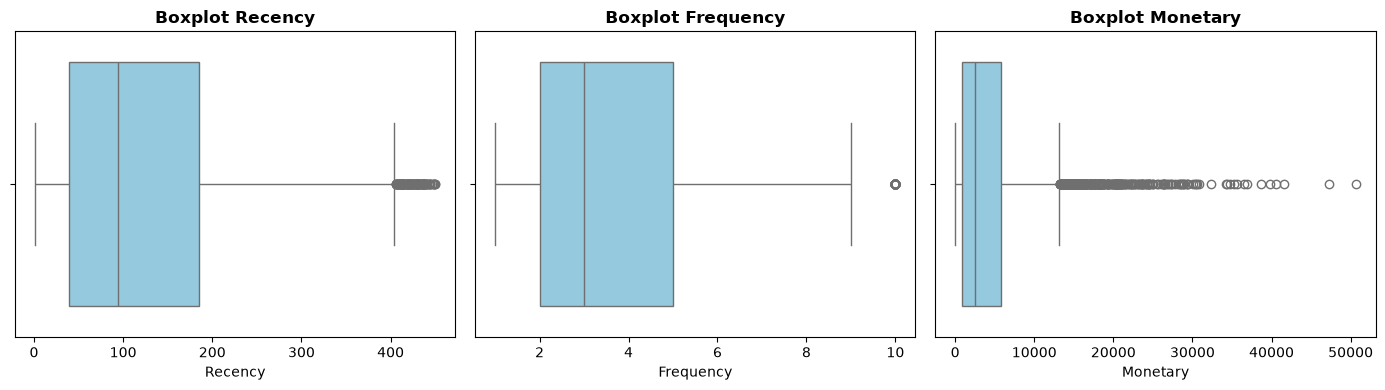

In [13]:
# Membuat Visualisasi Boxplot Pada Model RFM
rfm_features = ['Recency', 'Frequency', 'Monetary']
n_cols = 3
n_rows = (len(rfm_features) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()


for i, col in enumerate(rfm_features):
    sns.boxplot(data=rfm_df, x=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

In [14]:
# Identifikai Jumlah Outlier Pada Model RFM
def count_outliers_iqr(df, features):
    outlier_info = []

    for col in features:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        num_outliers = len(outliers)
        percentage = (num_outliers / len(df)) * 100

        outlier_info.append({
            "Feature": col,
            "Jumlah Outlier": num_outliers,
            "Persentase (%)": round(percentage, 2),
            "Batas Bawah (IQR)": round(lower_bound, 2),
            "Batas Atas (IQR)": round(upper_bound, 2)
        })

    return pd.DataFrame(outlier_info)

df_outliers = count_outliers_iqr(rfm_df, rfm_features)
df_outliers

,Feature,Jumlah Outlier,Persentase (%),Batas Bawah (IQR),Batas Atas (IQR)
0,Recency,107,2.17,-180.00,404.00
1,Frequency,92,1.87,-2.50,9.50
2,Monetary,328,6.66,-6457.96,13128.63


In [15]:
# Menghapus Outlier 
def filter_rfm_iqr(df, features):
    df_clean = df.copy()
    
    for col in features:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        
    return df_clean

rfm_features = ['Monetary']
df_cluster_clean = filter_rfm_iqr(rfm_df, rfm_features)

print(f"Jumlah data sebelum dibersihkan: {len(rfm_df)}")
print(f"Jumlah data setelah dibersihkan dengan IQR: {len(df_cluster_clean)}")

Jumlah data sebelum dibersihkan: 4927
Jumlah data setelah dibersihkan dengan IQR: 4599


# Exploratory Data Analysis

In [16]:
rfm_df.describe().round(2)

,Recency,Frequency,Monetary
count,4927.00,4927.00,4927.00
mean,125.59,3.41,4339.59
std,108.12,2.18,5237.22
min,1.00,1.00,14.28
25%,39.00,2.00,887.01
50%,94.00,3.00,2493.26
75%,185.00,5.00,5783.66
max,450.00,10.00,50628.15


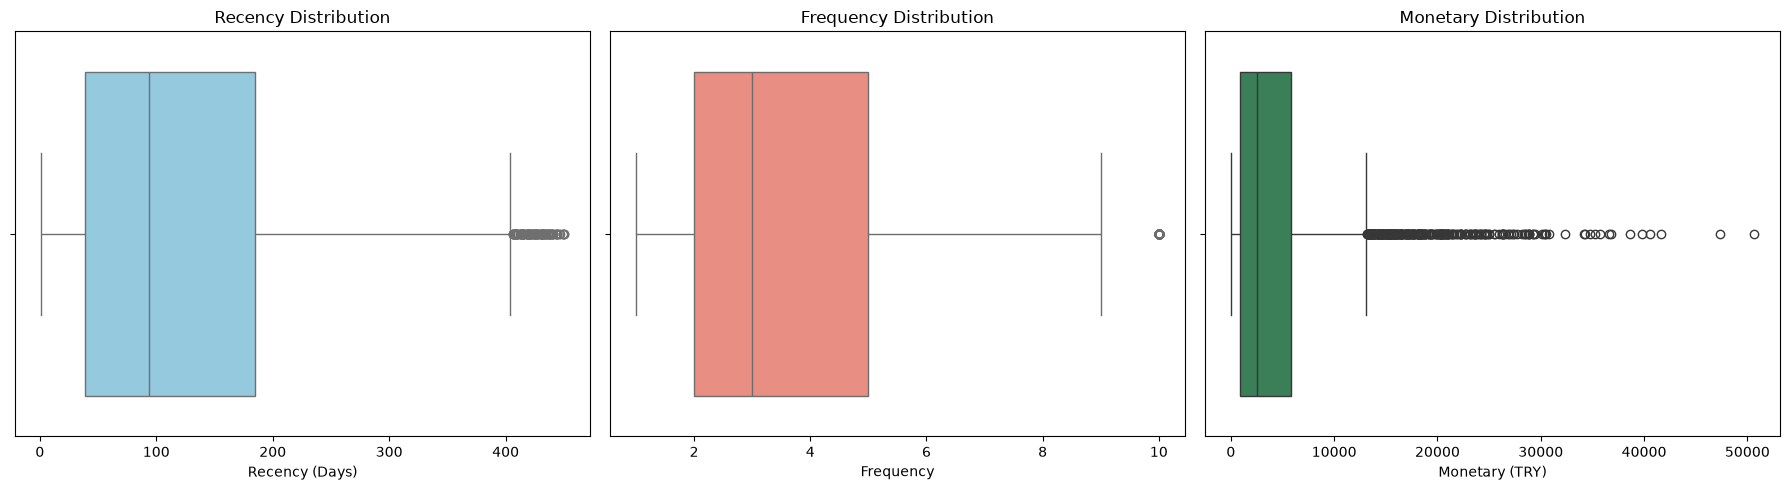

In [17]:
# Membuat Visualisasi untuk Distribusi Feature Recency, Frequency, dan Monetary
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box Plot Horizontal Recency
sns.boxplot(x=rfm_df['Recency'], ax=axes[0], color='skyblue')
axes[0].set_title('Recency Distribution')
axes[0].set_xlabel('Recency (Days)')

# Box Plot Horizontal Frequency
sns.boxplot(x=rfm_df['Frequency'], ax=axes[1], color='salmon')
axes[1].set_title('Frequency Distribution')
axes[1].set_xlabel('Frequency')

# Box Plot Horizontal Monetary
sns.boxplot(x=rfm_df['Monetary'], ax=axes[2], color='seagreen')
axes[2].set_title('Monetary Distribution')
axes[2].set_xlabel('Monetary (TRY)')

plt.tight_layout()
plt.show()

# Modeling

In [18]:
# Inisialisasi StandardScaler
scaler = StandardScaler()

# Melakukan Scaling Hanya pada Fitur RFM 
rfm_features = ['Recency', 'Frequency', 'Monetary']
X_scaled = scaler.fit_transform(df_cluster_clean[rfm_features])

# Mengubah Hasilnya Kembali Menjadi DataFrame
df_scaled = pd.DataFrame(X_scaled, columns=rfm_features, index=df_cluster_clean.index)

print("\nContoh hasil data setelah di-scaling (5 baris pertama):")
print(df_scaled.head())


Contoh hasil data setelah di-scaling (5 baris pertama):
    Recency  Frequency  Monetary
0 -0.157167  -0.108455 -0.344614
1  1.418123  -0.601812 -0.790989
2 -0.422768  -0.601812 -0.077642
3 -0.798273  -1.095168 -0.928037
4  1.372330  -0.108455 -0.272955


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


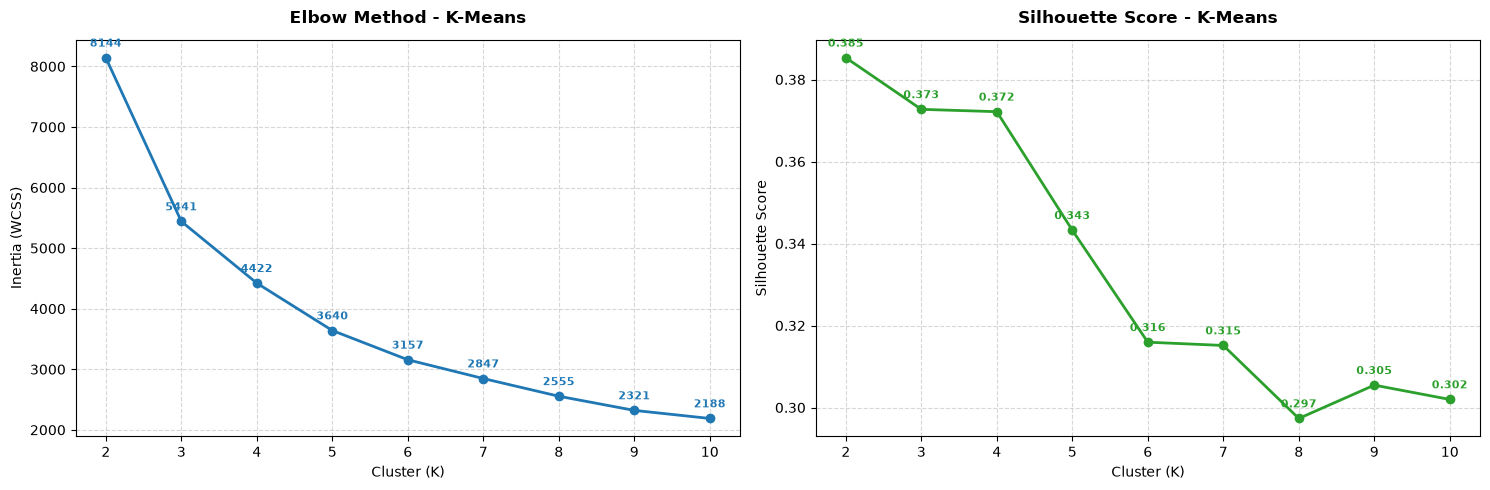

In [19]:
# Evaluasi Model K-Means
inertia_kmeans = []
silhouette_kmeans = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_kmeans = kmeans.fit_predict(X_scaled)
    
    inertia_kmeans.append(kmeans.inertia_)
    silhouette_kmeans.append(silhouette_score(X_scaled, labels_kmeans))


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Elbow Method (Inertia) ---
axes[0].plot(k_range, inertia_kmeans, marker='o', color='#1f77b4', linewidth=2, markersize=6)
axes[0].set_title('Elbow Method - K-Means', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Cluster (K)', fontsize=10)
axes[0].set_ylabel('Inertia (WCSS)', fontsize=10)
axes[0].set_xticks(k_range)
axes[0].grid(True, linestyle='--', alpha=0.5)

for k, val in zip(k_range, inertia_kmeans):
    axes[0].annotate(f'{val:.0f}', (k, val), textcoords="offset points", xytext=(0, 8), 
                     ha='center', fontsize=8, color='#1f77b4', fontweight='semibold')

# --- Plot 2: Silhouette Score ---
axes[1].plot(k_range, silhouette_kmeans, marker='o', color='#2ca02c', linewidth=2, markersize=6)
axes[1].set_title('Silhouette Score - K-Means', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Cluster (K)', fontsize=10)
axes[1].set_ylabel('Silhouette Score', fontsize=10)
axes[1].set_xticks(k_range)
axes[1].grid(True, linestyle='--', alpha=0.5)

for k, txt in zip(k_range, silhouette_kmeans):
    axes[1].annotate(f'{txt:.3f}', (k, txt), textcoords="offset points", xytext=(0, 8), 
                     ha='center', fontsize=8, color='#2ca02c', fontweight='semibold')

plt.tight_layout()
plt.show()

In [20]:
# Pembuatan Kluster
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df_cluster_clean['Cluster'] = kmeans.fit_predict(X_scaled)

df_cluster_clean.head()

,Customer_ID,Recency,Frequency,Monetary,Cluster
0,CUST_00001,112,3,2199.63,0
1,CUST_00002,284,2,809.90,1
2,CUST_00003,83,2,3030.81,0
3,CUST_00004,42,1,383.22,0
4,CUST_00005,279,3,2422.73,1


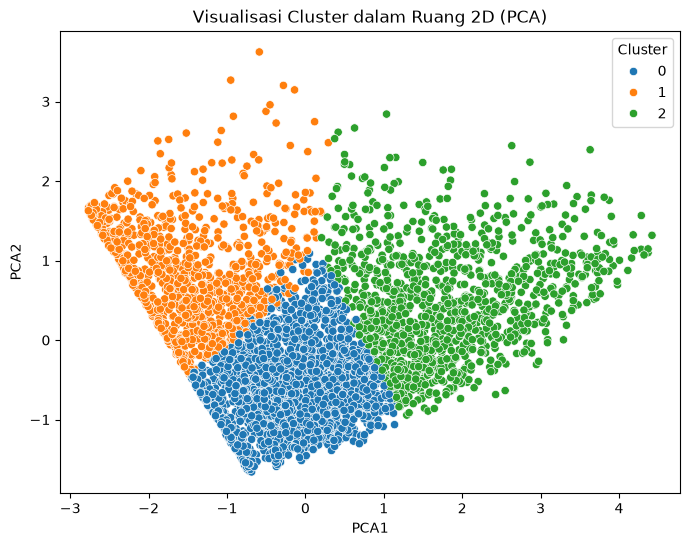

In [21]:
# Visualisasi PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

df_cluster_clean['PCA1'] = pca_result[:, 0]
df_cluster_clean['PCA2'] = pca_result[:, 1]

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_cluster_clean, x="PCA1", y="PCA2", hue="Cluster", palette="tab10")
plt.title("Visualisasi Cluster dalam Ruang 2D (PCA)")
plt.show()

# Business Profilling

In [22]:
# Agregasi perilaku tambahan "Unit_Price" & "Discount_Amount" per Customer_ID dari data transaksi asli (df)
customer_behavior_agg = df.groupby('Customer_ID').agg(
    Rata2_Unit_Price=('Unit_Price', 'mean'),
    Rata2_Discount=('Discount_Amount', 'mean')
).reset_index()

# Gabungkan data perilaku tersebut ke dataframe klaster bersih (df_cluster_clean)
df_profile_full = df_cluster_clean.merge(customer_behavior_agg, on='Customer_ID', how='inner')

# Buat tabel ringkasan profiling dikelompokkan berdasarkan nomor klaster
business_profiling = df_profile_full.groupby('Cluster').agg(
    Jumlah_Customer=('Customer_ID', 'count'),
    Recency_Rata2=('Recency', 'mean'),
    Frequency_Rata2=('Frequency', 'mean'),
    Monetary_Rata2=('Monetary', 'mean'),
    Rata2_Unit_Price=('Rata2_Unit_Price', 'mean'),
    Rata2_Discount=('Rata2_Discount', 'mean')
).reset_index()

business_profiling['Recency_Rata2'] = business_profiling['Recency_Rata2'].round(0).astype(int)
business_profiling['Frequency_Rata2'] = business_profiling['Frequency_Rata2'].round(0).astype(int)
business_profiling['Monetary_Rata2'] = business_profiling['Monetary_Rata2'].round(2)
business_profiling['Rata2_Unit_Price'] = business_profiling['Rata2_Unit_Price'].round(2)
business_profiling['Rata2_Discount'] = business_profiling['Rata2_Discount'].round(2)

# Hitung Persentase Jumlah Customer per Klaster terhadap total keseluruhan
business_profiling['Persentase_Customer (%)'] = (
    business_profiling['Jumlah_Customer'] / len(df_cluster_clean) * 100
).round(2)

print("=== TABEL BUSINESS PROFILING KLASTER PELANGGAN ===")
print(business_profiling.to_string(index=False))

=== TABEL BUSINESS PROFILING KLASTER PELANGGAN ===
 Cluster  Jumlah_Customer  Recency_Rata2  Frequency_Rata2  Monetary_Rata2  Rata2_Unit_Price  Rata2_Discount  Persentase_Customer (%)
       0             2278             82                3         1985.88            316.14           44.97                    49.53
       1             1131            289                2         1671.75            383.21           56.05                    24.59
       2             1190             68                6         7256.98            542.38           86.60                    25.88


In [24]:
# Menampilkan Top 3 Kategori Produk per Klaster Berdasarkan Jumlah Transaksi
df_transaksi_cluster = df.merge(df_cluster_clean[['Customer_ID', 'Cluster']], on='Customer_ID', how='inner')

print("\n=== TOP 3 KATEGORI PRODUK PER KLASTER (JUMLAH TRANSAKSI) ===")
for cluster in sorted(df_cluster_clean['Cluster'].unique()):
    sub_trans = df_transaksi_cluster[df_transaksi_cluster['Cluster'] == cluster]
    top_categories_count = sub_trans['Product_Category'].value_counts().head(3)
    
    print(f"Klaster {cluster}:")
    for cat, count in top_categories_count.items():
        print(f"   - {cat}: {count} transaksi")


=== TOP 3 KATEGORI PRODUK PER KLASTER (JUMLAH TRANSAKSI) ===
Klaster 0:
   - Books: 919 transaksi
   - Beauty: 869 transaksi
   - Food: 819 transaksi
Klaster 1:
   - Beauty: 287 transaksi
   - Books: 269 transaksi
   - Food: 267 transaksi
Klaster 2:
   - Sports: 911 transaksi
   - Home & Garden: 891 transaksi
   - Electronics: 890 transaksi
